# 4.1 Landmark-based models

In order to carry out primary tasks like localization or navigation, or more high-level tasks like interacting with humans, a mobile robot has to **perceive** its workspace. A variety of sensors can be used for that, as well as a number of probabilistic models for managing their behavior.

Typically, the sensors used onboard the robot do not deliver the exact truth of the quantities they are measuring, but a perturbed version. This is due to the working (physical) principles that govern the sensors behavior, and to the conditions of their workspaces (illumination, humidity, temperature, etc.). 

As an illustrative example of this, there is a popular European company called [SICK](https://www.sick.com/es/es/), which develops 2D LiDAR sensors (among other devices). One of its most popular sensors is the [TiM2xx one](https://www.sick.com/gb/en/catalog/products/lidar-and-radar-sensors/lidar-sensors/tim/tim240-2050300/p/p654443) (see left part of Fig. 1), which can be easily integrated into a robotic platform. If we take a look at the specifications about the performance of such device, we can check how this uncertainty about the sensor measurements is explicitly specified (systematic error and statistical error), as well as how these values depend on environmental conditions (see right part of Fig. 1). $\\[10pt]$

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/sick-laser.PNG" alt="">
  <figcaption>Fig. 1. Left, TiM2xx sensor from SICK. Right, performance details of such sensor.</figcaption>
</figure>    

$\\[5pt]$ To account for this behavior, sensors' measurements in probabilistic robotics will be modeled by... wait for it... a probability distribution: the measurement is a random variable $Z \sim p(z|v)$, where $z$ is one particular measurement (a realization of $Z$) and $v$ is the true (unknown) value. The sensor error is often modeled as Gaussian, that is, $p(z|v) = \mathcal{N}(z; v, \sigma^2)$, being $\sigma^2$ the measurement variance.

## 4.1.1 Dealing with landmark-based models

In different applications it is interesting for the robot to detect **landmarks** in its workspace and build internal representations of them, commonly referred to as maps. A landmark can be defined as a distinctive feature present in the environment, that can be used to perform localization, map building, or navigation, since they provide a fixed reference point in the environment. They can be of different nature:

- **Natural landmarks**: mountains, trees, rivers, rocks, etc.
- **Artificial landmarks**: buildings, signs, traffic lights, doors, windows, furniture, etc.
  - ***Purpose-built landmarks***: QR codes, [ArUco](https://www.uco.es/investiga/grupos/ava/portfolio/aruco/) codes, visual-patterns in general, RFID tags, beacons, etc.

Fig. 2 shows some examples of each type.
 
<center>
    <a id="figure"></a>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/types-of-landmarks.png" width="800">
    <figcaption>Fig. 2. Types of landmarks: natural, artificial and purpose-built (e.g. the pattern of three black circles used to locate a recharging station).</figcaption>
</center>
</br>
 
In both cases, landmarks or features like corners, blobs, etc. could also be extracted, e.g. using a camera.

In the case of maps consisting of a collection of landmarks, $\mathcal{M} = \mathbf{m} = \{\mathbf{m}_i\},\ i=1,\dots,N$, where $\mathbf{m}_i = [x_i, y_i]^T$ is the position of the $i$-th landmark, different types of sensors can be used to provide observations $\mathbf{z}_i$ of those landmarks:

- **Distance/range** (*e.g.* radio, GPS, etc.): $\\[2pt]$
  $\hspace{1cm}$ $z_i = r_i = h_i(\mathbf{x},\mathbf{m})+w_i$ $\\[2pt]$
- **Bearing** (*e.g.* camera): $\\[2pt]$
  $\hspace{1cm}$ $z_i = \alpha_i = h_i(\mathbf{x},\mathbf{m})+w_i$ $\\[2pt]$
- **Distance/range and bearing** (*e.g.* stereo, features in a scan, etc.) $\\[2pt]$
  $\hspace{1cm}$ $\mathbf{z}_i = [r_i,\alpha_i]^T = \mathbf{h}_i(\mathbf{x},\mathbf{m})+\mathbf{w}_i$ *(in this case, $\mathbf{h}_i(\mathbf{x},\mathbf{m})$ and $\mathbf{w}_i$ are 2D vectors)* $\\[2pt]$

where:

- $\mathbf{z}_i$ is an observation, $\mathbf{x}$ is the sensor pose, and $\mathbf{m}$ is the map of the environment (here, the set of landmarks),
- $\mathbf{h}(\mathbf{x},\mathbf{m})$ is the Observation (or measurement, or prediction) function: it predicts the value of the observation $\mathbf{z}_i$ given the state values $\mathbf{x}$ and $\mathbf{m}$, that is, the *ideal* measurement $\mathbf{v} = \mathbf{h}(\mathbf{x},\mathbf{m})$, and
- $\mathbf{w}$ is the measurement error, modeled by a zero-mean Gaussian distribution $\mathbf{w} \sim \mathcal{N}(\mathbf{0},Q)$, being $Q$ its covariance matrix.

In this way, the probability distribution $p(\mathbf{z}|\mathbf{x},\mathbf{m})$ modeling the sensor measurements results:

$$
p(\mathbf{z}|\mathbf{x},\mathbf{m}) = \mathcal{N}(\mathbf{z}; \mathbf{h}(\mathbf{x},\mathbf{m}), Q) = K \exp\{-\frac{1}{2}[\mathbf{h}(\mathbf{x},\mathbf{m})-\mathbf{z}]^T Q^{-1} [\mathbf{h}(\mathbf{x},\mathbf{m})-\mathbf{z}]\}
$$

where $K = 1/\sqrt{(2\pi)^k |Q|}$ is a normalization constant (it makes the pdf integrate to 1) and $k$ is the dimension of $\mathbf{z}$.

Recall that this probability is used, for example, to update our belief about the robot pose $\mathbf{x}$ after receiving an observation $\mathbf{z}$, by means of Bayes' theorem:

$$
p(\mathbf{x}|\mathbf{z},\mathbf{m}) = \frac{p(\mathbf{z}|\mathbf{x},\mathbf{m})\, p(\mathbf{x}|\mathbf{m})}{p(\mathbf{z}|\mathbf{m})} \propto p(\mathbf{z}|\mathbf{x},\mathbf{m})\, p(\mathbf{x}|\mathbf{m})
$$

In the localization chapter, this will be extended to the Bayes filter, which also takes the robot motion into account.

These types of maps and sensor measurements pose a new problem: **data association**, that is, which landmark $\mathbf{m}_i$ the observation $\mathbf{z}_i$ corresponds to:

$$\mathbf{h}_i(\mathbf{x},\mathbf{m})=\mathbf{h}(\mathbf{x},\mathbf{m}_i)$$

This problem is usually addressed by using the landmark descriptor (e.g. its visual features) or by applying Chi-squared tests, although for the sake of simplicity in this course we will consider it as solved. 

### Playing with landmarks and robot poses

In the rest of this section we will familiarize ourselves with the process of observing landmarks from robots located at certain poses, as well as the transformations needed to make use of these observations, that is, to express those observations into the world frame and backwards.

Some relevant concepts:

- **World frame**: $(x, y)$ coordinates from a selected point of reference $(0, 0)$ used to keep track of the robot's pose and landmarks within the map.
- **Observation**: Information from the real world provided by a sensor, from the point of view (*pov*) of a certain robot.
- **Range-bearing sensor**: Sensor model being used in this lesson. This kind of sensors detect how far an object is (its range $r$) and its orientation relative to the robot's one (its bearing $\alpha$), that is, they provide observations $\mathbf{z} = [r, \alpha]^T$.

The main tools to deal with those concepts are:

- the composition of two poses.
- the composition of a pose and a landmark.
- the propagation of uncertainty through the Jacobians of these compositions.

We will address several problems of incremental complexity. In all of them, it is important to have in mind how the composition of a (robot) pose and a landmark point works:


<center>
    <a id="figure"></a>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/fig4-1-pose-landmark-composition.png">
    <figcaption>Fig. 3. Composition of a pose and a landmark point.</figcaption>
</center>

In [1]:
# In case of using Google Colab, mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # Change directory to this chapter's folder in your Drive copy of the course repo:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_robotics_2027/Chapter 04. Robot sensing'
except ImportError:
    pass

#%matplotlib widget
%matplotlib inline

# IMPORTS

import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")
from utils.PlotEllipse import PlotEllipse
from utils.DrawRobot import DrawRobot
from utils.tcomp import tcomp
from utils.tinv import tinv, jac_tinv1 as jac_tinv
from utils.Jacobians import J1, J2

### **<span style="color:green"><b><i>ASSIGNMENT 1: Expressing an observed landmark in coordinates of the world frame</i></b></span>** <a id="4211"></a>

Let’s consider a robot R1 at a perfectly known pose $\mathbf{x}_1 = [1, 2, 0.5]^T$ (no uncertainty at this point) which observes a landmark $\mathbf{m}$ with a range-bearing (polar) sensor. The sensor provides the measurement $[4\text{ m}, 0.7\text{ rad}]^T$ and is affected by a zero-mean Gaussian error with covariance $\Sigma_{\mathbf{z}^1_p} = \text{diag}([0.25, 0.04])$ (in the robot frame). Therefore, we model the observation as a Gaussian centered at the measured value: $\mathbf{z}^1_p \sim \mathcal{N}(\bar{\mathbf{z}}^1_p, \Sigma_{\mathbf{z}^1_p})$, with mean $\bar{\mathbf{z}}^1_p = [4\text{ m}, 0.7\text{ rad}]^T$. The scenario is the one in Fig. 4.

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/assignment_1_scenario.png"/>
    <figcaption>Fig. 4. Illustration of the scenario in assignment 1.</figcaption>
</center>

**You are tasked to** compute the Gaussian probability distribution $\mathbf{m}^1 \sim \mathcal{N}(\bar{\mathbf{m}}^1, \Sigma_{\mathbf{m}^1})$ (mean and covariance) of the landmark observation in the world frame (the same as the robot) and plot its corresponding ellipse (in green, $\sigma=1$). Concretely, you have to complete the ``to_world_frame()`` function, and modify the demo code to show the ellipse representing the uncertainty.

To do so, recall that the landmark position in the world frame is the composition of the robot pose, $\mathbf{x}_1$, and the landmark observation expressed in Cartesian coordinates in the robot frame, $\mathbf{z}^1_c$:

$$
\mathbf{m}^1 = \mathbf{x}_1 \oplus \mathbf{z}^1_c = \mathbf{f}(\mathbf{x}_1, \mathbf{z}^1_c)
$$

Then, by first-order uncertainty propagation (that is, linearizing $\mathbf{f}$ around the means), the mean and the covariance of the landmark in the world frame are:

$$
\bar{\mathbf{m}}^1 = \bar{\mathbf{x}}_1 \oplus \bar{\mathbf{z}}^1_c
$$

$$
\Sigma_{\mathbf{m}^1} = \frac{\partial \mathbf{m}^1}{\partial \mathbf{x}_1} \ \Sigma_{\mathbf{x}_1} \ \left( \frac{\partial \mathbf{m}^1}{\partial \mathbf{x}_1} \right)^T +
     \frac{\partial \mathbf{m}^1}{\partial \mathbf{z}^1_c} \ \Sigma_{\mathbf{z}^1_c} \ \left( \frac{\partial \mathbf{m}^1}{\partial \mathbf{z}^1_c} \right)^T
$$

where $\Sigma_{\mathbf{x}_1}$ is the covariance of the robot pose $\mathbf{x}_1$ (zero in this assignment), and $\Sigma_{\mathbf{z}^1_c}$ is the covariance of the observation in Cartesian coordinates. Note that this expression assumes that the robot pose $\mathbf{x}_1$ and the observation $\mathbf{z}^1_c$ are independent (uncorrelated), which is why their contributions to $\Sigma_{\mathbf{m}^1}$ simply add up.

Mathematical pill: the Jacobian of a function $\mathbf{f}(\mathbf{a}) = [f_1, \dots, f_k]^T$ of $n$ variables $\mathbf{a} = [a_1, \dots, a_n]^T$ is the $k \times n$ matrix:

$$
\frac{\partial \mathbf{f}}{\partial \mathbf{a}} =
\begin{bmatrix}
    \frac{\partial f_1}{\partial a_1} & \cdots & \frac{\partial f_1}{\partial a_n} \\
    \vdots & \ddots & \vdots \\
    \frac{\partial f_k}{\partial a_1} & \cdots & \frac{\partial f_k}{\partial a_n}
\end{bmatrix}
$$

The Jacobians $\frac{\partial \mathbf{m}^1}{\partial \mathbf{x}_1}$ ($2 \times 3$) and $\frac{\partial \mathbf{m}^1}{\partial \mathbf{z}^1_c}$ ($2 \times 2$) are the same ones previously used to compose two poses in *robot motion*, but with a reduced size since **while working with landmarks the orientation is meaningless, only the position matters**. The functions ``J1()`` and ``J2()`` implement these Jacobians for you.

However, the sensor does not provide $\mathbf{z}^1_c$ and $\Sigma_{\mathbf{z}^1_c}$, but the observation in polar coordinates, $\mathbf{z}^1_p$, and its covariance $\Sigma_{\mathbf{z}^1_p}$. So, before composing, you have to express the observation in Cartesian coordinates. A sensor measurement in polar coordinates ($\mathbf{z}_p=[r,\alpha]^T$) is expressed in Cartesian coordinates ($\mathbf{z}_c=[z_x,z_y]^T$) by:

$$
\mathbf{z}_c = \begin{bmatrix} z_x \\ z_y \end{bmatrix}
    = \begin{bmatrix} r \cos\alpha \\ r \sin\alpha \end{bmatrix}
    = \mathbf{f}(\mathbf{z}_p)
$$

and its covariance is obtained, again, by propagating the uncertainty, in this case through the Jacobian of this function:

$$
\Sigma_{\mathbf{z}^1_c} = \frac{\partial \mathbf{z}_c}{\partial \mathbf{z}_p} \ \Sigma_{\mathbf{z}^1_p} \ \left( \frac{\partial \mathbf{z}_c}{\partial \mathbf{z}_p} \right)^T
$$

Example: $\\[5pt]$

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/result_1.PNG" />
    <figcaption>Fig. 5. Pose of a robot (without uncertainty) and position of an observed landmark with its associated uncertainty.</figcaption>
</center>

In [2]:
def to_world_frame(x1_w, Qx1_w, z1_p_r, W1):
    """ Convert the observation z1_p_r to the world frame

        Args:
            x1_w: Pose of the robot x_1 (in world frame)
            Qx1_w: Covariance Sigma_x_1 of the robot pose
            z1_p_r: Observation z^1_p of a landmark (polar coordinates) from the robot's perspective
            W1: Covariance Sigma_z^1_p of the sensor in polar coordinates

        Returns:
            z1_w: Position of the landmark m^1 in the world frame (its mean)
            Wz1: Covariance Sigma_m^1 associated to z1_w
    """

    # Definition of useful variables
    r, a = z1_p_r[0,0], z1_p_r[1,0]
    s, c = np.sin(a), np.cos(a)

    # Jacobian dz_c/dz_p to convert the measurement uncertainty from polar to cartesian coordinates
    Jac_pol_car = np.array([
        [c, -r*s],
        [s,  r*c]
    ])

    # Build a tuple with:
    # z1_car_rel[0]: coordinates of the sensor measurement in cartesian coordinates relative to robot position (z^1_c)
    # z1_car_rel[1]: its associated uncertainty expressed in cartesian coordinates (Sigma_z^1_c)
    z1_car_rel = (
            np.vstack([r*c, r*s]), # position
            Jac_pol_car@W1@Jac_pol_car.T # uncertainty
            )

    z1_ext = np.vstack([z1_car_rel[0], 0]) # Extends z1 for its usage in the Jacobian functions J1 and J2

    # Build the Jacobians
    Jac_ap = J1(x1_w ,z1_ext)[0:2,:] # Jacobian dm^1/dx_1 for expressing the uncertainty in the robot pose in a global frame
    Jac_aa = J2(x1_w ,z1_ext)[0:2,0:2] # This one (dm^1/dz^1_c) expresses the uncertainty in the measurement in a global frame

    z1_w = tcomp(x1_w ,z1_ext)[0:2,[0]] # Compute coordinates of the landmark in the world
    Wz1 = (Jac_ap @ Qx1_w @ Jac_ap.T
          + Jac_aa @ z1_car_rel[1] @ Jac_aa.T) # Finally, propagate the covariance!

    return z1_w, Wz1

----	Exercise 4.1.1	----
z1_w = [2.44943102 5.72815634]'
Wz1_w = 
[[ 0.58879177 -0.13171532]
 [-0.13171532  0.30120823]]



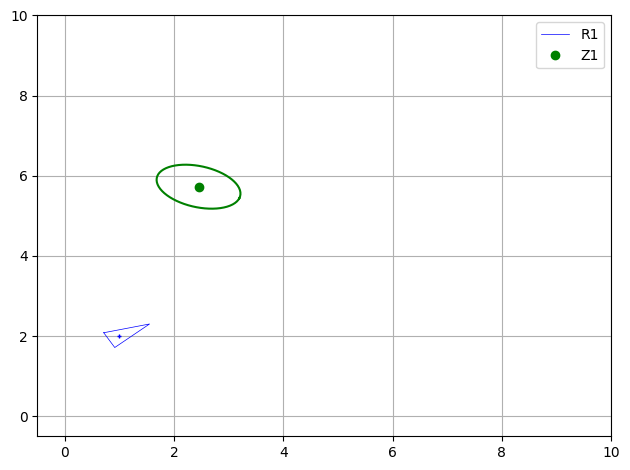

In [3]:
# Robot
x1_w = np.vstack([1, 2, 0.5]) # Robot R1 pose x_1
Qx1_w = np.zeros((3, 3)) # Robot pose covariance matrix (uncertainty) Sigma_x_1

# Landmark observation
z1_p_r = np.vstack([4., .7]) # Measurement/Observation z^1_p
W1 = np.diag([0.25, 0.04]) # Sensor noise covariance Sigma_z^1_p

# Express the landmark observation in the world frame (mean and covariance of m^1)
z1_w, Wz1 = to_world_frame(x1_w, Qx1_w, z1_p_r, W1)

# Visualize the results
fig, ax = plt.subplots()
plt.xlim([-.5, 10])
plt.ylim([-.5, 10])
plt.grid()
plt.tight_layout()

DrawRobot(fig, ax, x1_w, label='R1', color='blue')

ax.plot(z1_w[0, 0], z1_w[1, 0], 'o', label='Z1', color='green')
PlotEllipse(fig, ax, z1_w, Wz1, color='green')

plt.legend()
print('----\tExercise 4.1.1\t----\n'+
      'z1_w = {}\'\n'.format(z1_w.flatten())
      + 'Wz1_w = \n{}\n'.format(Wz1))

<span style="color:blue">Expected results for demo:</span>


```
---- Exercise 4.1.1 ----
z1_w = [2.44943102 5.72815634]'
Wz1_w = 
[[ 0.58879177 -0.13171532]
 [-0.13171532  0.30120823]]
```

### **<span style="color:green"><b><i>ASSIGNMENT 2: Adding uncertainty to the robot position</i></b></span>**

Now, let’s assume that the robot pose is not known, but it is a RV that follows a Gaussian probability distribution: $\mathbf{x}_1 \sim \mathcal{N}(\bar{\mathbf{x}}_1, \Sigma_{\mathbf{x}_1})$, with $\bar{\mathbf{x}}_1 = [1, 2, 0.5]^T$ and $\Sigma_{\mathbf{x}_1} = \text{diag}([0.08, 0.6, 0.02])$.

1. Compute the covariance matrix $\Sigma_{\mathbf{m}^1}$ of the landmark in the world frame and plot it as an ellipse centered at the mean $\bar{\mathbf{m}}^1$ (in green, $\sigma = 1$). Plot also the covariance of the robot pose (in blue, $\sigma = 1$).

2. Compare the covariance with that obtained in the previous case.  $\\[5pt]$

Example: $\\[5pt]$

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/result_2.PNG" />
    <figcaption>Fig. 6. Pose of a robot and position of an observed landmark, along with their associated uncertainties.</figcaption>
</center>

---- Exercise 4.1.2 ----
Wz1_w = 
[[ 0.94677477 -0.23978943]
 [-0.23978943  0.94322523]]



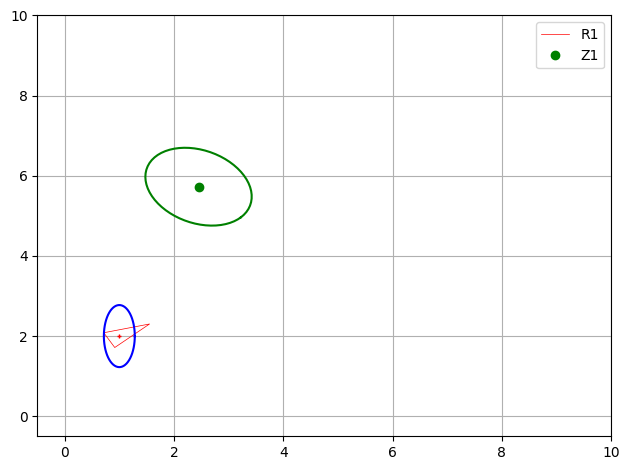

In [4]:
# Robot
x1_w = np.vstack([1, 2, 0.5]) # Robot R1 pose x_1
Qx1_w = np.diag([0.08,0.6,0.02])  # Robot pose covariance matrix (uncertainty) Sigma_x_1

# Landmark observation
z1_p_r = np.vstack([4., .7]) # Measurement/Observation z^1_p
W1 = np.diag([0.25, 0.04]) # Sensor noise covariance Sigma_z^1_p

# Express the landmark observation in the world frame (mean and covariance of m^1)
z1_w, Wz1 = to_world_frame(x1_w, Qx1_w, z1_p_r, W1)

# MATPLOTLIB
fig, ax = plt.subplots()
plt.xlim([-.5, 10])
plt.ylim([-.5, 10])
plt.grid()
plt.tight_layout()

fig.canvas.draw()

DrawRobot(fig, ax, x1_w, label='R1', color='red')
PlotEllipse(fig, ax, x1_w, Qx1_w, color='blue')

ax.plot(z1_w[0, 0], z1_w[1, 0], 'o', label='Z1', color='green')
PlotEllipse(fig, ax, z1_w, Wz1, color='green')

plt.legend()
print('---- Exercise 4.1.2 ----\n'+
      'Wz1_w = \n{}\n'.format(Wz1))


<span style="color:blue">Expected results for demo:</span>

```
---- Exercise 4.1.2 ----
Wz1_w = 
[[ 0.94677477 -0.23978943]
 [-0.23978943  0.94322523]]
```

### Comparación de las covarianzas de los Assignments 1 y 2

El punto 2 del Assignment 2 pide comparar $\Sigma_{\mathbf{m}^1}$ con la del caso anterior. La celda siguiente calcula, para la pose del robot y para el landmark en los dos casos, los semiejes de la elipse de $1\sigma$ (raíces de los valores propios) y su área ($\pi\sqrt{|\Sigma|}$), separa el término que aporta la incertidumbre del robot, $\frac{\partial \mathbf{m}^1}{\partial \mathbf{x}_1}\Sigma_{\mathbf{x}_1}\left(\frac{\partial \mathbf{m}^1}{\partial \mathbf{x}_1}\right)^T$, y comprueba con una simulación de Monte Carlo (20 000 muestras de pose y observación) que la covarianza linealizada es una buena aproximación. Todo va dentro de una función para no cambiar las variables globales que usan las celdas siguientes.

Robot R1 (bloque x-y)    : semiejes 1σ = [0.775 0.283] m, área 1σ = 0.688 m²
m^1 con pose exacta  (A1): semiejes 1σ = [0.8 0.5] m, área 1σ = 1.257 m²
m^1 con pose incierta (A2): semiejes 1σ = [1.088 0.84 ] m, área 1σ = 2.872 m²

Término añadido por la pose del robot (A2 - A1) =
 [[ 0.358  -0.1081]
 [-0.1081  0.642 ]]
Su traza = σx² + σy² + σθ²·r² = 1.0

Media Monte Carlo = [2.41  5.617]  (linealizada: [2.449 5.728] )
Covarianza Monte Carlo =
 [[ 0.918 -0.225]
 [-0.225  0.964]]


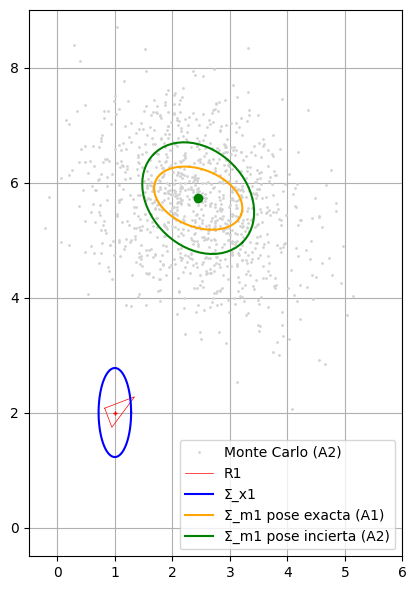

In [5]:
def compare_assignments_1_2(n_samples=20000, seed=0):
    x1 = np.vstack([1., 2., 0.5])
    Q_known = np.zeros((3, 3))
    Q_unc = np.diag([0.08, 0.6, 0.02])
    z1 = np.vstack([4., .7])
    W = np.diag([0.25, 0.04])

    m1, S_known = to_world_frame(x1, Q_known, z1, W)
    _, S_unc = to_world_frame(x1, Q_unc, z1, W)

    def describe(name, S):
        axes = np.sqrt(np.linalg.eigvalsh(S))[::-1]
        print(f'{name}: semiejes 1σ = {axes.round(3)} m, área 1σ = {np.pi*np.sqrt(np.linalg.det(S)):.3f} m²')

    describe('Robot R1 (bloque x-y)    ', Q_unc[0:2, 0:2])
    describe('m^1 con pose exacta  (A1)', S_known)
    describe('m^1 con pose incierta (A2)', S_unc)
    print('\nTérmino añadido por la pose del robot (A2 - A1) =\n', (S_unc - S_known).round(4))
    print('Su traza = σx² + σy² + σθ²·r² =', 0.08 + 0.6 + 0.02*z1[0, 0]**2)

    # Monte Carlo: sample the robot pose and the polar observation, and compose them exactly
    rng = np.random.default_rng(seed)
    xs = rng.multivariate_normal(x1.ravel(), Q_unc, n_samples)
    zs = rng.multivariate_normal(z1.ravel(), W, n_samples)
    ang = xs[:, 2] + zs[:, 1]
    ms = np.c_[xs[:, 0] + zs[:, 0]*np.cos(ang), xs[:, 1] + zs[:, 0]*np.sin(ang)]
    print('\nMedia Monte Carlo =', ms.mean(axis=0).round(3), ' (linealizada:', m1.ravel().round(3), ')')
    print('Covarianza Monte Carlo =\n', np.cov(ms.T).round(3))

    fig, ax = plt.subplots(figsize=(6, 6))
    plt.xlim([-.5, 6])
    plt.ylim([-.5, 9])
    plt.grid()
    ax.set_aspect('equal')
    ax.plot(ms[::20, 0], ms[::20, 1], '.', color='lightgray', markersize=2, label='Monte Carlo (A2)')
    DrawRobot(fig, ax, x1, label='R1', color='red')
    PlotEllipse(fig, ax, x1, Q_unc, color='blue', label='Σ_x1')
    PlotEllipse(fig, ax, m1, S_known, color='orange', label='Σ_m1 pose exacta (A1)')
    PlotEllipse(fig, ax, m1, S_unc, color='green', label='Σ_m1 pose incierta (A2)')
    ax.plot(m1[0, 0], m1[1, 0], 'o', color='green')
    plt.legend(loc='lower right')
    plt.tight_layout()

compare_assignments_1_2()

**Conclusiones de la comparación:**

- **Assignment 1 (pose exacta):** los semiejes son exactamente $0.8$ y $0.5$ m. El semieje radial es $\sigma_r = \sqrt{0.25} = 0.5$ m y el tangencial es $r\,\sigma_\alpha = 4 \cdot \sqrt{0.04} = 0.8$ m: el error angular del sensor se convierte en un error lateral proporcional a la distancia. La rotación al marco del mundo no cambia los semiejes, solo orienta la elipse.
- **Assignment 2 (pose incierta):** a la covarianza anterior se le **suma** el término $J_x\Sigma_{\mathbf{x}_1}J_x^T$, que es semidefinido positivo, así que la elipse nunca puede encogerse. Su traza es $0.08 + 0.6 + 0.02 \cdot 4^2 = 1.0$ m²: la incertidumbre en $x$ e $y$ del robot pasa tal cual, y la de su orientación ($\sigma_\theta^2 = 0.02$) actúa como un brazo de palanca de longitud $r = 4$ m.
- El área de la elipse pasa de 1.26 a 2.87 m², y es mucho mayor que la del propio robot (0.69 m²).
- La nube de Monte Carlo cae sobre la elipse verde, y su covarianza muestral es muy parecida a la linealizada: la aproximación de primer orden es buena con estas incertidumbres.
- La media de Monte Carlo queda unos 0.1 m más cerca del robot que la linealizada. Es el efecto de la no linealidad: con un error angular gaussiano de varianza $\sigma^2$, $E[\cos(\theta+\alpha)] = \cos(\bar\theta+\bar\alpha)\,e^{-\sigma^2/2}$, así que, en media, el punto observado se «acerca». Aquí $\sigma^2 = 0.02 + 0.04 = 0.06$ y el factor es 0.97 (unos 0.12 m a 4 m de distancia), pequeño frente a semiejes de casi 1 m.

### **<span style="color:green"><b><i>ASSIGNMENT 3: Combining observations of the same landmark</i></b></span>**

Assume now that the robot moves to a new pose $\mathbf{x}_2 \sim \mathcal{N}(\bar{\mathbf{x}}_2, \Sigma_{\mathbf{x}_2})$, with $\bar{\mathbf{x}}_2 = [6\text{ m}, 4\text{ m}, 2.1\text{ rad}]^T$ and $\Sigma_{\mathbf{x}_2} = \text{diag}([0.20, 0.09, 0.03])$, and takes a measurement $[4\text{ m}, 0.3\text{ rad}]^T$ of the landmark with the same sensor, so the observation is $\mathbf{z}^2_p \sim \mathcal{N}(\bar{\mathbf{z}}^2_p, \Sigma_{\mathbf{z}^2_p})$, with $\bar{\mathbf{z}}^2_p = [4\text{ m}, 0.3\text{ rad}]^T$ and $\Sigma_{\mathbf{z}^2_p} = \Sigma_{\mathbf{z}^1_p}$. **You have to**:

1. Use the previously implemented `to_world_frame()` function to compute the position and uncertainty of the landmark from both measurements in the world frame, that is, $\mathbf{m}^1 \sim \mathcal{N}(\bar{\mathbf{m}}^1, \Sigma_{\mathbf{m}^1})$ and $\mathbf{m}^2 \sim \mathcal{N}(\bar{\mathbf{m}}^2, \Sigma_{\mathbf{m}^2})$.
2. Plot the robots and the two measurements along with their uncertainty (ellipses) in the world frame.
3. Combine both observations within the `combine_pdfs()` function, and show the resultant combined observation $\mathbf{m} \sim \mathcal{N}(\bar{\mathbf{m}}, \Sigma_{\mathbf{m}})$ along with its associated uncertainty.

Hint: since both observations are independent, the pdf that combines them is proportional to the product of their pdfs:

$$
p(\mathbf{m}) \propto \mathcal{N}(\mathbf{m};\, \bar{\mathbf{m}}^1, \Sigma_{\mathbf{m}^1})\; \mathcal{N}(\mathbf{m};\, \bar{\mathbf{m}}^2, \Sigma_{\mathbf{m}^2})
$$

and the product of two Gaussian pdfs is, up to a normalization constant, another Gaussian pdf $\mathcal{N}(\mathbf{m};\, \bar{\mathbf{m}}, \Sigma_{\mathbf{m}})$. Find out how its mean $\bar{\mathbf{m}}$ and covariance $\Sigma_{\mathbf{m}}$ are computed from those of the two observations, and implement it in `combine_pdfs()`.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/fig4-1-2.PNG" width="400" alt="">
  <figcaption>Fig. 7. Poses of R1 and R2, the two observations of the landmark (Z1, Z2) and their combination (Z3), with their uncertainty ellipses.</figcaption>
</figure>    

In [6]:
def combine_pdfs(z1_w, Wz1_w, z2_w, Wz2_w):
    """ Method to combine the pdfs associated with two observations of the same landmark.

        Args:
            z1_w: Landmark m^1 observed in cartesian coordinates (world frame) from Robot 1
            Wz1_w: Covariance Sigma_m^1 associated to the landmark.
            z2_w: Landmark m^2 observed in cartesian coordinates (world frame) from Robot 2
            Wz2_w: Covariance Sigma_m^2 associated to the landmark.
        Returns:
            z: Combined observation m (its mean)
            W_z: Covariance Sigma_m associated to z
    """
    # Product of two Gaussians: the information matrices (inverse covariances) add up,
    # and the mean is the information-weighted average of both means
    inv_Wz1 = np.linalg.inv(Wz1_w)
    inv_Wz2 = np.linalg.inv(Wz2_w)

    W_z = np.linalg.inv(inv_Wz1 + inv_Wz2)
    z = W_z @ (inv_Wz1 @ z1_w + inv_Wz2 @ z2_w)

    return z, W_z



----	Exercise 4.1.3	----
z2_w = [3.05042514 6.70185272]'
Qz2 = 
[[0.84693794 0.4333316 ]
 [0.4333316  0.81306206]]

----	Exercise 4.1.3 part 2	----
z_w = [2.58757252 6.15534036]'
Wz_w = 
[[0.37966125 0.07773125]
 [0.07773125 0.36999739]]



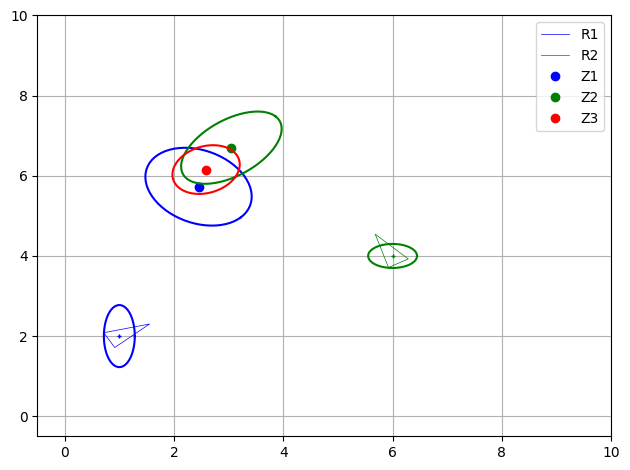

In [7]:
x2_w = np.vstack([6., 4., 2.1])
Qx2_w = np.diag([0.20, 0.09, 0.03])

z2_p_r = np.vstack([4., .3])
Wz2_p_r = np.diag([0.25, 0.04])

z1_w, Qz1 = to_world_frame(x1_w, Qx1_w, z1_p_r, W1)
z2_w, Qz2 = to_world_frame(x2_w, Qx2_w, z2_p_r, Wz2_p_r)

# Show results
fig, ax = plt.subplots()
plt.xlim([-.5, 10])
plt.ylim([-.5, 10])
plt.grid()
plt.tight_layout()

fig.canvas.draw()

DrawRobot(fig, ax, x1_w, label='R1', color='blue')
PlotEllipse(fig, ax, x1_w, Qx1_w, color='blue')

DrawRobot(fig, ax, x2_w, label='R2', color='green')
PlotEllipse(fig, ax, x2_w, Qx2_w, color='green')

ax.plot(z1_w[0, 0], z1_w[1, 0], 'o', label='Z1', color='blue')
PlotEllipse(fig, ax, z1_w, Qz1, color='blue')

ax.plot(z2_w[0, 0], z2_w[1, 0], 'o', label='Z2', color='green')
PlotEllipse(fig, ax, z2_w, Qz2, color='green')

z_w, Wz_w = combine_pdfs(z1_w, Qz1, z2_w, Qz2)
ax.plot(z_w[0, 0], z_w[1, 0], 'o', label='Z3', color='red')
PlotEllipse(fig, ax, z_w, Wz_w, color='red')

plt.legend()

# Print results
print( '----\tExercise 4.1.3\t----\n'+
    'z2_w = {}\'\n'.format(z2_w.flatten())+
    'Qz2 = \n{}\n'.format(Qz2)
    )

# Print results
print( '----\tExercise 4.1.3 part 2\t----\n'+
    'z_w = {}\'\n'.format(z_w.flatten())+
    'Wz_w = \n{}\n'.format(Wz_w)
    )

<span style="color:blue">Expected outputs:</span>

### Sensor measurement from x2

```
---- Exercise 4.1.3 ----
z2_w = [3.05042514 6.70185272]'
Qz2 = 
[[0.84693794 0.4333316 ]
 [0.4333316  0.81306206]]
```

### Combined information
```
---- Exercise 4.1.3 part 2 ----
z_w = [2.58757252 6.15534036]'
Wz_w = 
[[0.37966125 0.07773125]
 [0.07773125 0.36999739]]
```

### Comprobaciones de la fusión

La celda siguiente comprueba tres cosas sobre la combinación del Assignment 3:

1. Que la fórmula usada (producto de gaussianas en forma de **información**) es equivalente a la forma de **Kalman**: $K = \Sigma_{\mathbf{m}^1}(\Sigma_{\mathbf{m}^1}+\Sigma_{\mathbf{m}^2})^{-1}$, $\bar{\mathbf{m}} = \bar{\mathbf{m}}^1 + K(\bar{\mathbf{m}}^2-\bar{\mathbf{m}}^1)$, $\Sigma_{\mathbf{m}} = (I-K)\Sigma_{\mathbf{m}^1}$.
2. Que las dos observaciones son **compatibles**: la distancia de Mahalanobis al cuadrado entre ambas medias, $d^2 = (\bar{\mathbf{m}}^2-\bar{\mathbf{m}}^1)^T(\Sigma_{\mathbf{m}^1}+\Sigma_{\mathbf{m}^2})^{-1}(\bar{\mathbf{m}}^2-\bar{\mathbf{m}}^1)$, debe estar por debajo del umbral $\chi^2_2$ al 95 % (5.991). Es el test que se usa para la asociación de datos.
3. Que la incertidumbre de la fusión es menor que la de cada observación (determinante y traza).

In [8]:
def check_fusion():
    m1, S1 = to_world_frame(x1_w, Qx1_w, z1_p_r, W1)
    m2, S2 = to_world_frame(x2_w, Qx2_w, z2_p_r, Wz2_p_r)
    m, S = combine_pdfs(m1, S1, m2, S2)

    K = S1 @ np.linalg.inv(S1 + S2)
    m_k = m1 + K @ (m2 - m1)
    S_k = (np.eye(2) - K) @ S1
    print('Forma de información == forma de Kalman:', np.allclose(m, m_k) and np.allclose(S, S_k))

    d = m2 - m1
    d2 = (d.T @ np.linalg.inv(S1 + S2) @ d).item()
    print(f'Distancia de Mahalanobis² entre m^1 y m^2: {d2:.3f} (umbral χ²(2) al 95 %: 5.991)')

    for name, M in [('m^1', S1), ('m^2', S2), ('m (fusión)', S)]:
        print(f'{name:11s}: det Σ = {np.linalg.det(M):.4f}, traza Σ = {np.trace(M):.3f}')

check_fusion()

Forma de información == forma de Kalman: True
Distancia de Mahalanobis² entre m^1 y m^2: 0.677 (umbral χ²(2) al 95 %: 5.991)
m^1        : det Σ = 0.8355, traza Σ = 1.890
m^2        : det Σ = 0.5008, traza Σ = 1.660
m (fusión) : det Σ = 0.1344, traza Σ = 0.750


### <font color="blue"><b><i>Thinking about it (1)</i></b></font>

Having completed the code above, you will be able to **answer the following questions**:

- When working with landmarks, why do we ignore the information regarding orientation?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Porque un landmark se modela como un <b>punto</b>, <b>m</b> = [m<sub>x</sub>, m<sub>y</sub>]<sup>T</sup>: tiene posición pero no orientación propia, y el sensor de rango y rumbo tampoco mide ninguna (solo r y α). Por eso el resultado de x<sub>1</sub> ⊕ <b>z</b><sub>c</sub> se recorta a sus dos primeras componentes (<code>[0:2]</code>), los jacobianos se reducen a 2×3 (∂<b>m</b>/∂<b>x</b>, <code>J1(...)[0:2,:]</code>) y 2×2 (∂<b>m</b>/∂<b>z</b><sub>c</sub>, <code>J2(...)[0:2,0:2]</code>), y el 0 que se añade en <code>z1_ext</code> es solo un relleno para poder reutilizar <code>tcomp</code>, <code>J1</code> y <code>J2</code>, que trabajan con poses de 3 componentes. Ojo: lo que se ignora es la orientación del <b>landmark</b>, no la del robot. θ<sub>1</sub> sigue siendo imprescindible, porque gira la observación del marco del robot al del mundo, y su incertidumbre aparece en la tercera columna de ∂<b>m</b>/∂<b>x</b>.</i></p>

- In the two first assignments we computed the covariance matrix $\Sigma_{\mathbf{m}^1}$ of the landmark observed by robot $R1$ in two different cases: when the $R1$ pose was perfectly known, and having some uncertainty about it. Which covariance matrix was bigger? Is it bigger than that of the robot? Why?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La del Assignment 2. Con la pose exacta, Σ<sub><b>m</b><sup>1</sup></sub> solo contiene el error del sensor y su elipse tiene semiejes σ<sub>r</sub> = 0.5 m (radial) y r·σ<sub>α</sub> = 4·0.2 = 0.8 m (tangencial), con un área de 1.26 m². Con la pose incierta se le <b>suma</b> el término (∂<b>m</b>/∂<b>x</b>)Σ<sub><b>x</b><sub>1</sub></sub>(∂<b>m</b>/∂<b>x</b>)<sup>T</sup>, que es semidefinido positivo, así que la covarianza solo puede crecer: los semiejes pasan a 1.09 y 0.84 m y el área a 2.87 m². También es mayor que la del robot (semiejes 0.77 y 0.28 m, área 0.69 m²), porque la del landmark acumula tres fuentes: la incertidumbre en x e y del robot, que pasa tal cual; la de su orientación, que se amplifica con la distancia como un brazo de palanca (σ<sub>θ</sub><sup>2</sup>·r<sup>2</sup> = 0.02·16 = 0.32 m²); y el ruido del propio sensor. Observar un landmark desde una pose incierta nunca puede dar una posición más precisa que la del robot.</i></p>

- In the last assignment we got two different pdfs associated to the same landmark. Is that a contradiction? How did you manage to combine these two *pieces of information*?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>No es una contradicción. Ninguna de las dos pdfs es «la verdad»: cada una es una estimación de la misma posición desconocida, con su propia incertidumbre, y las medias difieren en menos de lo que permiten esas incertidumbres. La distancia de Mahalanobis al cuadrado entre ellas es 0.68, muy por debajo del umbral χ<sup>2</sup> de 2 grados de libertad al 95 % (5.99), así que son compatibles con ser el mismo landmark. Como las dos observaciones son independientes, la pdf que combina ambas es proporcional a su <b>producto</b>, que es otra gaussiana con Σ<sub><b>m</b></sub> = (Σ<sub><b>m</b><sup>1</sup></sub><sup>-1</sup> + Σ<sub><b>m</b><sup>2</sup></sub><sup>-1</sup>)<sup>-1</sup> y media <b>m̄</b> = Σ<sub><b>m</b></sub>(Σ<sub><b>m</b><sup>1</sup></sub><sup>-1</sup><b>m̄</b><sup>1</sup> + Σ<sub><b>m</b><sup>2</sup></sub><sup>-1</sup><b>m̄</b><sup>2</sup>): se suman las informaciones y la media es un promedio ponderado por ellas, de modo que pesa más la observación más precisa en cada dirección. El resultado (2.59, 6.16) queda entre las dos medias y su covarianza es menor que cualquiera de las dos (determinante 0.134 frente a 0.836 y 0.501). Es la misma operación que el paso de corrección de un filtro de Kalman.</i></p>

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Un asistente de programación basado en IA generativa (Claude Code con Claude Opus 5.5)</i></p>
- **What I asked AI to help with (bullets):**
  <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li>Ayuda para completar <code>to_world_frame()</code>, <code>combine_pdfs()</code>, <code>inverse_composition1()</code> y <code>predicted_obs_from_pov()</code>, y comprobar que las salidas coinciden con las esperadas.</li><li>Explicaciones de la propagación de la incertidumbre de polares a cartesianas y del producto de gaussianas.</li><li>Las partes opcionales: descripción de sensores y un ejemplo de los modelos de observación de escaneo.</li></ul></div>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>He revisado el código contra las ecuaciones del notebook, he comprobado que todas las salidas coinciden con las esperadas y he validado la covarianza linealizada con Monte Carlo antes de quedarme con la solución.</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this robotics notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

*AI used for the review: el mismo asistente de programación (Claude Code).*

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Σ<sub>m</sub> suma dos términos: sensor y pose; nunca puede ser menor.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Fusionar gaussianas suma informaciones; equivale a la corrección de un filtro de Kalman.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Álgebra matricial NumPy con vectores columna (3×1) y operador <code>@</code> coherentes.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Reutiliza funciones (<code>tcomp</code>, <code>J1</code>, <code>J2</code>) ampliando el landmark con un cero.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Normalizar el ángulo predicho α̂ y evitar <code>inv</code> explícitas (usar <code>solve</code>).</i></p>

Finally, **do you agree with them?**, **would you have selected others?** 
    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Estoy de acuerdo con los cinco. Los teóricos recogen las dos ideas de la práctica: la incertidumbre del landmark acumula la del robot y la del sensor, y combinar dos observaciones independientes reduce la incertidumbre, que es justo lo que hará la corrección del EKF en localización. La mejora también es real: en <code>predicted_obs_from_pov()</code>, α̂ = atan2(·) − θ<sub>2</sub> no se normaliza a (−π, π]; aquí sale 0.59 rad y no importa, pero con otras poses podría salir, por ejemplo, 5.9 rad en lugar de −0.39 rad, y la innovación respecto a una medida real sería absurda. Habría que aplicar <code>AngleWrap</code>. Invertir matrices 2×2 bien condicionadas no da problemas, pero con covarianzas casi singulares sería más robusto usar <code>np.linalg.solve</code>. Como alternativa, habría señalado que <code>combine_pdfs()</code> supone independencia entre las dos observaciones, y si el robot R2 obtuvo su pose a partir de R1, eso dejaría de ser cierto.</i></p>

## <span style="color:green">OPTIONAL PARTS</span>

### <span style="color:green">OPTIONAL: Getting the relative pose between two robots</span>

Another robot `R2` is at pose $\mathbf{x}_2 \sim \mathcal{N}(\bar{\mathbf{x}}_2, \Sigma_{\mathbf{x}_2})$, with $\bar{\mathbf{x}}_2 = [6\text{ m}, 4\text{ m}, 2.1\text{ rad}]^T$ and $\Sigma_{\mathbf{x}_2} = \text{diag}([0.20, 0.09, 0.03])$. Plot $\mathbf{x}_2$ and its ellipse (covariance) in green ($\sigma = 1$). **Compute the relative pose $\mathbf{x}_{12}$ between `R1` and `R2`**, including its associated uncertainty $\Sigma_{\mathbf{x}_{12}}$. This scenario is shown in Fig. 8.

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/assignment_3_scenario.png"/>
    <figcaption>Fig. 8. Illustration of the scenario in this assignment.</figcaption>
</center>

This relative pose can be obtained in two different ways:

- **Through the composition of poses**, but using $\ominus \mathbf{x}_1$ instead of $\mathbf{x}_1$. Implement it in ``inverse_composition1()``.

Mean, being $\ominus \mathbf{x}_1 = [x_{\ominus 1}, y_{\ominus 1}, \theta_{\ominus 1}]^T$ and $\mathbf{x}_2 = [x_2, y_2, \theta_2]^T$:

$$
\mathbf{x}_{12} = \ominus \mathbf{x}_1 \oplus \mathbf{x}_2 = \mathbf{f}(\ominus \mathbf{x}_1, \mathbf{x}_2) =
\begin{bmatrix}
 x_{\ominus 1} + x_2 \cos \theta_{\ominus 1} - y_2 \sin \theta_{\ominus 1} \\
 y_{\ominus 1} + x_2 \sin \theta_{\ominus 1} + y_2 \cos \theta_{\ominus 1} \\
 \theta_{\ominus 1} + \theta_2
\end{bmatrix}
$$

Covariance:

$$
\Sigma_{\mathbf{x}_{12}} = \frac{\partial \mathbf{x}_{12}}{\partial \ominus \mathbf{x}_1} \frac{\partial \ominus \mathbf{x}_1}{\partial \mathbf{x}_1} \Sigma_{\mathbf{x}_1} \left( \frac{\partial \ominus \mathbf{x}_1}{\partial \mathbf{x}_1} \right)^T \left( \frac{\partial \mathbf{x}_{12}}{\partial \ominus \mathbf{x}_1} \right)^T
+
\frac{\partial \mathbf{x}_{12}}{\partial \mathbf{x}_2} \Sigma_{\mathbf{x}_2} \left( \frac{\partial \mathbf{x}_{12}}{\partial \mathbf{x}_2} \right)^T
$$

Applying the chain rule, it can be rewritten as:

$$
\Sigma_{\mathbf{x}_{12}} = \frac{\partial \mathbf{x}_{12}}{\partial \ominus \mathbf{x}_1} \Sigma_{\ominus \mathbf{x}_1} \left( \frac{\partial \mathbf{x}_{12}}{\partial \ominus \mathbf{x}_1} \right)^T
+
\frac{\partial \mathbf{x}_{12}}{\partial \mathbf{x}_2} \Sigma_{\mathbf{x}_2} \left( \frac{\partial \mathbf{x}_{12}}{\partial \mathbf{x}_2} \right)^T
$$

Being:

$$
\frac{\partial \mathbf{x}_{12}}{\partial \ominus \mathbf{x}_1} =
\begin{bmatrix}
1 & 0 & -x_2 \sin \theta_{\ominus 1} - y_2 \cos \theta_{\ominus 1} \\
0 & 1 & x_2 \cos \theta_{\ominus 1} - y_2 \sin \theta_{\ominus 1} \\
0 & 0 & 1
\end{bmatrix}
\; \; \; \; \; \frac{\partial \mathbf{x}_{12}}{\partial \mathbf{x}_2} =
\begin{bmatrix}
\cos \theta_{\ominus 1} & -\sin \theta_{\ominus 1} & 0\\
\sin \theta_{\ominus 1} & \cos \theta_{\ominus 1} & 0\\
0 & 0 & 1
\end{bmatrix}
$$

$$
\frac{\partial \ominus \mathbf{x}_1}{\partial \mathbf{x}_1} =
\begin{bmatrix}
-\cos \theta_1 & -\sin \theta_1 & x_1 \sin \theta_1 - y_1 \cos \theta_1 \\
\sin \theta_1 & -\cos \theta_1 & x_1 \cos \theta_1 + y_1 \sin \theta_1 \\
0 & 0 & -1
\end{bmatrix}
\; \; \; \; \; \Sigma_{\ominus \mathbf{x}_1} = \frac{\partial \ominus \mathbf{x}_1}{\partial \mathbf{x}_1} \Sigma_{\mathbf{x}_1} \left( \frac{\partial \ominus \mathbf{x}_1}{\partial \mathbf{x}_1} \right)^T
$$

where $\mathbf{x}_1 = [x_1, y_1, \theta_1]^T$. $\\[5pt]$

- **Using the inverse composition of poses**, that is $\mathbf{x}_{12} = \ominus \mathbf{x}_1 \oplus \mathbf{x}_2 = \mathbf{x}_2 \ominus \mathbf{x}_1$. This one is given for you in ``inverse_composition2()``.

In [9]:
def inverse_composition1(x1_w, Qx1_w, x2_w, Qx2_w):
    jac_inv_x = jac_tinv(x1_w)

    inv_r1 = (
        tinv(x1_w),
        jac_inv_x @ Qx1_w @ jac_inv_x.T
    )

    jac_x12_inv = J1(inv_r1[0], x2_w)
    jac_x12_x2 = J2(inv_r1[0], x2_w)

    x12_w = tcomp(inv_r1[0], x2_w)

    Qx12_w = (
            jac_x12_inv@inv_r1[1]@jac_x12_inv.T
            + jac_x12_x2@Qx2_w@jac_x12_x2.T
        )

    return x12_w, Qx12_w

In [10]:
def inverse_composition2(x1_w, Qx1_w, x2_w, Qx2_w):
    dx, dy = x2_w[0, 0]-x1_w[0, 0], x2_w[1, 0]-x1_w[1, 0]
    a = x2_w[2, 0] - x1_w[2, 0]
    c, s = np.cos(x1_w[2, 0]), np.sin(x1_w[2, 0])

    x12_w = np.array([
        [dx*c + dy*s],
        [-dx*s + dy*c],
        [a]])
    
    jac_x12_r1 = np.array([
        [-c, -s, -dx*s + dy*c],
        [s, -c, -dx*c - dy*s],
        [0, 0, -1]
    ])

    jac_x12_r2 = np.array([
        [c, s, 0],
        [-s, c, 0],
        [0, 0, 1]
    ])

    Qx12_w = jac_x12_r1@Qx1_w@jac_x12_r1.T + jac_x12_r2@Qx2_w@jac_x12_r2.T

    return x12_w, Qx12_w

In [11]:
# Robot R1
x1_w = np.vstack([1., 2., 0.5])
Qx1_w = np.diag([0.08, 0.6, 0.02])

# Robot R2
x2_w = np.vstack([6., 4., 2.1])
Qx2_w = np.diag([0.20, 0.09, 0.03])

# Obtain the relative pose x12 between both robots through the composition of poses
x12_w, Qx12_w = inverse_composition1(x1_w, Qx1_w, x2_w, Qx2_w)
print( '----\tWith method 1\t----\n'+
        'x12_w = {}\'\n'.format(x12_w.flatten())+
        'Qx12_w = \n{}\n'.format(Qx12_w))

# Obtain the relative pose x12 between both robots through the inverse composition of poses
x12_w, Qx12_w = inverse_composition2(x1_w, Qx1_w, x2_w, Qx2_w)
print( '----\tWith method 2\t----\n'+
        'x12_w = {}\'\n'.format(x12_w.flatten())+
        'Qx12_w = \n{}\n'.format(Qx12_w))

----	With method 1	----
x12_w = [ 5.34676389 -0.64196257  1.6       ]'
Qx12_w = 
[[0.38248035 0.24115    0.01283925]
 [0.24115    1.16751965 0.10693528]
 [0.01283925 0.10693528 0.05      ]]

----	With method 2	----
x12_w = [ 5.34676389 -0.64196257  1.6       ]'
Qx12_w = 
[[0.38248035 0.24115    0.01283925]
 [0.24115    1.16751965 0.10693528]
 [0.01283925 0.10693528 0.05      ]]



<span style="color:blue">Expected results:</span>
 ```
 x12_w = [ 5.34676389 -0.64196257  1.6       ]'
 
 Qx12_w = 
 [[0.38248035 0.24115    0.01283925]
 [0.24115    1.16751965 0.10693528]
 [0.01283925 0.10693528 0.05      ]]
 ```

<span style="color:green">***END OF OPTIONAL PART***</span>

### <span style="color:green">OPTIONAL: Predicting an observation from the second robot</span>

According to the information (provided by R1) that we have about the position of the landmark $\mathbf{m}$ in the world coordinates (its location $\bar{\mathbf{m}}^1 = [m_x, m_y]^T$ and its associated uncertainty $\Sigma_{\mathbf{m}^1}$), compute the *predicted observation* $\hat{\mathbf{z}}^2_p = [\hat{r}, \hat{\alpha}]^T$ that a range-bearing sensor mounted on `R2` would provide, along with its covariance $\Sigma_{\hat{\mathbf{z}}^2_p}$. The image below shows this scenario.

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/assignment_4_scenario.png"/>
    <figcaption>Fig. 9. Illustration of the scenario in this practical case.</figcaption>
</center>


To do so, recall that the range-bearing model for taking measurements from the pose $\mathbf{x}_2 = [x_2, y_2, \theta_2]^T$ of `R2` is $\mathbf{z}^2_p = \mathbf{h}(\mathbf{x}_2, \mathbf{m}) + \mathbf{w}$. At this point, ignore the noise $\mathbf{w}$, so the predicted observation is *(Note: use [`np.arctan2()`](https://numpy.org/doc/stable/reference/generated/numpy.arctan2.html) for computing the angle)*:

$$
\hat{\mathbf{z}}^2_p = \begin{bmatrix} \hat{r} \\ \hat{\alpha} \end{bmatrix} =
\mathbf{h}(\mathbf{x}_2, \bar{\mathbf{m}}^1) =
\begin{bmatrix} \sqrt{(m_x-x_2)^2+(m_y-y_2)^2} \\ \text{atan}\left(\frac{m_y-y_2}{m_x-x_2}\right) - \theta_2 \end{bmatrix}
$$

Then, you need to compute the covariance of the predicted observation in polar coordinates, $\Sigma_{\hat{\mathbf{z}}^2_p}$. For that, first compute its covariance in cartesian coordinates in the `R2` frame, where the predicted observation is $\hat{\mathbf{z}}^2_c = \ominus \mathbf{x}_2 \oplus \mathbf{m}^1$:

$$
\Sigma_{\hat{\mathbf{z}}^2_c} = \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \ominus \mathbf{x}_2} \frac{\partial \ominus \mathbf{x}_2}{\partial \mathbf{x}_2} \ \Sigma_{\mathbf{x}_2} \ \left( \frac{\partial \ominus \mathbf{x}_2}{\partial \mathbf{x}_2} \right)^T \left( \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \ominus \mathbf{x}_2} \right)^T +
\frac{\partial \hat{\mathbf{z}}^2_c}{\partial \mathbf{m}^1} \ \Sigma_{\mathbf{m}^1} \ \left( \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \mathbf{m}^1} \right)^T
$$

Applying the chain rule, it can be rewritten as:

$$
\Sigma_{\hat{\mathbf{z}}^2_c} = \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \ominus \mathbf{x}_2} \Sigma_{\ominus \mathbf{x}_2} \left( \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \ominus \mathbf{x}_2} \right)^T + \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \mathbf{m}^1} \ \Sigma_{\mathbf{m}^1} \ \left( \frac{\partial \hat{\mathbf{z}}^2_c}{\partial \mathbf{m}^1} \right)^T
$$

Once you have the covariance expressed in cartesian coordinates, you can express it in polar coordinates by means of the following Jacobian:

$$
\frac{\partial \hat{\mathbf{z}}^2_p}{\partial \hat{\mathbf{z}}^2_c} =
\begin{bmatrix}
    \cos{\hat{\alpha}}  & \sin{\hat{\alpha}} \\
    -\sin{\hat{\alpha}} / \hat{r}  & \cos{\hat{\alpha}} / \hat{r}
\end{bmatrix}
$$

In [12]:
def predicted_obs_from_pov(x1_w, Qx1_w, z1_w, Wz1_w):
    """ Method to translate a pose+covariance in the world frame to an observation.

        This method only translates the landmark to the pov of the robot.
        It does not simulate a new observation.

        Args:
            x1_w: Pose of the robot which acts as pov (x_2 in the text)
            Qx1_w: Covariance of the robot (Sigma_x_2)
            z1_w: Landmark observed in cartesian coordinates (world frame) (m^1)
            Wz1_w: Covariance associated to the landmark (Sigma_m^1).
        Returns:
            z2_pr: Predicted observation of z1_w from pov of x1_w (polar coordinates)
            W2_p: Covariance associated to z2_pr
    """

    # Take a measurement using the range-bearing model
    z2_pr = np.vstack([
            np.sqrt((z1_w[0, 0]-x1_w[0, 0])**2 + (z1_w[1, 0]-x1_w[1, 0])**2), # distance
            np.arctan2(z1_w[1, 0]-x1_w[1, 0], z1_w[0, 0]-x1_w[0, 0]) - x1_w[2, 0] # angle
        ])

    # Obtain the uncertainty in the R2 reference frame using the composition of a pose and a landmark:
    z1_ext = np.vstack([z1_w, 0]) # Prepare position and uncertainty shapes to the ones expected by inverse_composition
    Wz1_w_ext = np.pad(Wz1_w, [(0, 1), (0, 1)], mode='constant')
    _, Wz1_r = inverse_composition1(x1_w, Qx1_w, z1_ext, Wz1_w_ext)
    W2_c = Wz1_r[0:2,0:2]

    # Jacobian from cartesian to polar at z2p_r
    theta = z2_pr[1, 0]
    s, c = np.sin(theta), np.cos(theta)
    r = z2_pr[0, 0]

    Jac_car_pol = np.array([
        [c, s],
        [-s/r, c/r]
    ])

    # Finally, propagate the uncertainty to polar coordinates in the
    # robot frame
    W2_p = Jac_car_pol@W2_c@Jac_car_pol.T

    return z2_pr, W2_p

In [13]:
x2_w = np.vstack([6., 4., 2.1])
Qx2_w = np.diag([0.20, 0.09, 0.03])

z2_pr, W2_p = predicted_obs_from_pov(x2_w, Qx2_w, z1_w, Wz1)
print( '---- Results ----\n'+
    'z2p_r = {}\'\n'.format(z2_pr.flatten())+
    'W2_p = \n{}\n'.format(W2_p)    
)

---- Results ----
z2p_r = [3.94880545 0.58862004]'
W2_p = 
[[ 1.31374309 -0.02614814]
 [-0.02614814  0.08555399]]



<span style="color:blue">Expected output:</span>
```
---- Results ----
z2p_r = [3.94880545 0.58862004]'
W2_p = 
[[ 1.31374309 -0.02614814]
 [-0.02614814  0.08555399]]
```

### <font color="blue"><b><i>Thinking about it (2)</i></b></font>

 - When predicting an observation of $\mathbf{m}$ from the second robot $R2$, why did we need to use the Jacobian $\partial \hat{\mathbf{z}}^2_p / \partial \hat{\mathbf{z}}^2_c$?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Porque la composición ⊖<b>x</b><sub>2</sub> ⊕ <b>m</b><sup>1</sup> da la observación predicha y su covarianza en coordenadas <b>cartesianas</b> del marco de R2, [ẑ<sub>x</sub>, ẑ<sub>y</sub>]<sup>T</sup>, pero el sensor mide en <b>polares</b>, [r, α]<sup>T</sup>. Para poder comparar la predicción con una medida real (la innovación de un filtro de Kalman, o el test de Mahalanobis para la asociación de datos) las dos tienen que estar en el mismo espacio y con su covarianza en ese espacio. El paso de cartesianas a polares, r = √(ẑ<sub>x</sub><sup>2</sup>+ẑ<sub>y</sub><sup>2</sup>), α = atan2(ẑ<sub>y</sub>, ẑ<sub>x</sub>), no es lineal, así que la covarianza no se puede transformar directamente: se linealiza con el jacobiano ∂ẑ<sub>p</sub>/∂ẑ<sub>c</sub> = [[cos α̂, sin α̂], [−sin α̂ / r̂, cos α̂ / r̂]] y se propaga como J Σ J<sup>T</sup>. Es el camino inverso al del Assignment 1, y su jacobiano es la inversa del de polares a cartesianas. La división entre r̂ hace que la misma incertidumbre lateral en metros produzca menos incertidumbre angular cuanto más lejos está el landmark.</i></p>

<span style="color:green">***END OF OPTIONAL PART***</span>

## <span style="color:green">OPTIONAL</span>

<span style="color:green">As commented, a number of sensors can be mounted on a mobile robot. In the robotic sensing lecture we discussed some of the most popular ones. As an optional exercise, you can look for interesting information about any of them (or any one not listed below) and further describe it here to complete your knowledge.</span>

- **Beacons**: emisores (radio, ultrasonidos, infrarrojos, balizas reflectantes) colocados en posiciones conocidas. El robot mide la distancia o el rumbo a varios y calcula su posición por **trilateración** (distancias) o **triangulación** (ángulos). Necesitan modificar el entorno, pero son precisos y no acumulan error.
  - **GPS**: un caso de balizas a escala global. Cada satélite emite su posición y la hora de su reloj atómico. El receptor mide el tiempo de vuelo a cada uno, $r_i = c\,\Delta t_i$ (pseudodistancia), y resuelve 4 incógnitas $(x, y, z)$ y el desfase de su propio reloj, por lo que necesita **al menos 4 satélites**. El error típico es de 2–5 m, por el retardo en la ionosfera y troposfera, la geometría de los satélites (DOP) y el multitrayecto en ciudad. Con correcciones diferenciales (DGPS) baja a menos de 1 m y con RTK a pocos cm. No funciona en interiores.
- **Range sensors**: miden la distancia al obstáculo más cercano en una dirección.
  - **Sonar**: emite un pulso de ultrasonidos y mide el tiempo hasta el eco: $d = \frac{c\,t}{2}$, con $c \approx 343$ m/s en el aire (depende de la temperatura). Es barato, pero el haz es un cono ancho (unos 15–30°), así que no se sabe exactamente en qué punto del cono está el obstáculo. Además sufre **reflexiones especulares** (si el haz incide oblicuamente sobre una pared lisa, el eco no vuelve y se lee una distancia mayor o el máximo) e interferencias entre varios sonares (*crosstalk*), y tiene una frecuencia de medida baja.
  - **Infrared**: emite luz infrarroja y mide la distancia por **triangulación** (posición del punto reflejado en un detector) o por tiempo de vuelo. Tiene un haz estrecho y es rápido, pero tiene poco alcance (de cm a pocos m), su medida depende del color y el material de la superficie y le afecta la luz solar.
  - **Laser scanner (LiDAR)**: un haz láser que gira y mide la distancia por tiempo de vuelo o desfase en cientos de direcciones por vuelta. Da un **escaneo** $\mathbf{z} = [z_1, \dots, z_K]$ con resolución angular de hasta 0.25°, precisión de mm a cm y alcance de decenas de metros (por ejemplo, el Hokuyo de la teoría tiene un campo de visión de 270°). Los 3D (varias capas, como en los coches autónomos) dan una nube de puntos. Sus problemas son los cristales, espejos y superficies negras, y el precio.
- **Cameras**: proyectan la escena 3D en una imagen 2D. Una cámara monocular da el **rumbo** (*bearing*) a un punto, pero no su distancia, que se pierde en la proyección; con dos cámaras (estéreo) se recupera por triangulación. Dan muchísima información (color, textura, reconocimiento de objetos y personas, marcadores ArUco o QR como landmarks), pero dependen de la iluminación y requieren mucho cómputo.
- **RGB-D cameras**: una cámara de color más un sensor de profundidad por luz estructurada (Kinect v1) o tiempo de vuelo (Kinect v2, Azure Kinect), que da la distancia en cada píxel. Son baratas y muy útiles en interiores para SLAM y reconocimiento, pero tienen poco alcance (unos 0.5–5 m) y fallan con luz solar directa.

<span style="color:green">***END OF OPTIONAL PART***</span>

## <span style="color:green">OPTIONAL</span>

<span style="color:green">An alternative to *landmark observation models* are *scan observation* ones, which work with scan-based sensors. Below, the three most popular ones are listed. Surf the internet for some code illustrating any of them, and include it in the notebook with a brief description of how it works and its purpose. You could also implement an example using these models.</span>

## Scan observation models

Scan observation models $p(\mathbf{z}|\mathbf{x},\mathbf{m})$ are used when the sensor mounted on the robot provides a scan $\mathbf{z} = [z_1, \dots, z_K]^T$ measuring distance and angle to obstacles in the workspace, *e.g.* a laser range finder. In this case, the map is given as a discrete representation (typically, a grid map, where each cell is described by its position and whether it is free of obstacles or occupied, or a segment-based map), and data association is not explicitly addressed.

En los tres modelos se suele suponer que los $K$ rayos son independientes dada la pose y el mapa, así que $p(\mathbf{z}|\mathbf{x},\mathbf{m}) = \prod_{k=1}^{K} p(z_k|\mathbf{x},\mathbf{m})$. En la práctica se suman logaritmos para no tener problemas numéricos con el producto de muchos números pequeños.

#### Beam model

Modela **físicamente** cada rayo. Para la pose $\mathbf{x}$ se calcula, con *ray casting* sobre el mapa, la distancia ideal $z_k^*$ hasta el primer obstáculo, y la medida real $z_k$ se modela como una mezcla de cuatro distribuciones con pesos $z_{hit} + z_{short} + z_{max} + z_{rand} = 1$:

$$p(z_k|\mathbf{x},\mathbf{m}) = z_{hit}\,p_{hit} + z_{short}\,p_{short} + z_{max}\,p_{max} + z_{rand}\,p_{rand}$$

- $p_{hit} = \mathcal{N}(z_k; z_k^*, \sigma_{hit}^2)$ (truncada a $[0, z_{max}]$): el rayo llega al obstáculo esperado, con ruido de medida.
- $p_{short} = \lambda e^{-\lambda z_k}$ para $z_k < z_k^*$: un obstáculo inesperado (una persona) corta el rayo antes.
- $p_{max}$: un pico en $z_{max}$ cuando el rayo no vuelve (cristales, superficies negras, reflexión especular).
- $p_{rand} = 1/z_{max}$: lecturas aleatorias inexplicables.

Es el más fiel, pero es caro (un *ray casting* por rayo y pose) y poco suave: un pequeño cambio de pose puede cambiar mucho $z_k^*$ si el rayo pasa rozando una esquina.

#### Likelihood field

En vez de seguir el rayo, solo se mira **dónde cae su extremo**. El punto final del rayo $k$ en el mundo es $\mathbf{x} \oplus [z_k\cos\alpha_k, z_k\sin\alpha_k]^T$, y se calcula su distancia $d_k$ al obstáculo más cercano del mapa (que se precalcula una vez para todo el mapa con una transformada de distancia). Entonces:

$$p(z_k|\mathbf{x},\mathbf{m}) = z_{hit}\,\mathcal{N}(d_k; 0, \sigma_{hit}^2) + \frac{z_{rand}}{z_{max}}$$

y los rayos con $z_k = z_{max}$ se descartan. Es mucho más rápido y suave que el *beam model* (no hay *ray casting*), aunque ignora que un rayo no puede atravesar paredes. Es el que usa, por ejemplo, AMCL en ROS.

#### Scan matching

No usa un modelo probabilístico de cada rayo sino que **alinea** el escaneo actual con un escaneo de referencia (o con el mapa) buscando la transformación rígida $(\Delta x, \Delta y, \Delta\theta)$ que mejor los superpone. El algoritmo más conocido es **ICP** (*Iterative Closest Point*): empareja cada punto con el más cercano del otro escaneo, calcula la rotación y traslación que minimizan la suma de distancias al cuadrado (en forma cerrada, con una SVD) y repite hasta converger. El resultado es una medida de la pose relativa, $\mathbf{z} = \Delta\mathbf{x}$, que se usa como una «odometría láser» mucho más precisa que la de las ruedas, o como observación $p(\mathbf{z}|\mathbf{x}) = \mathcal{N}(\mathbf{z}; \ominus\mathbf{x}_{ref}\oplus\mathbf{x}, \Sigma)$. Necesita una buena estimación inicial porque puede converger a un mínimo local.

#### Ejemplo implementado

Las celdas siguientes implementan una versión simplificada de los tres modelos sobre un mapa de rejilla sencillo (una habitación con una caja): se simula un escaneo desde una pose real, se dibuja la mezcla del *beam model* para un rayo, se evalúa la verosimilitud del *likelihood field* para muchas posiciones candidatas y se recupera con ICP el desplazamiento entre dos escaneos.

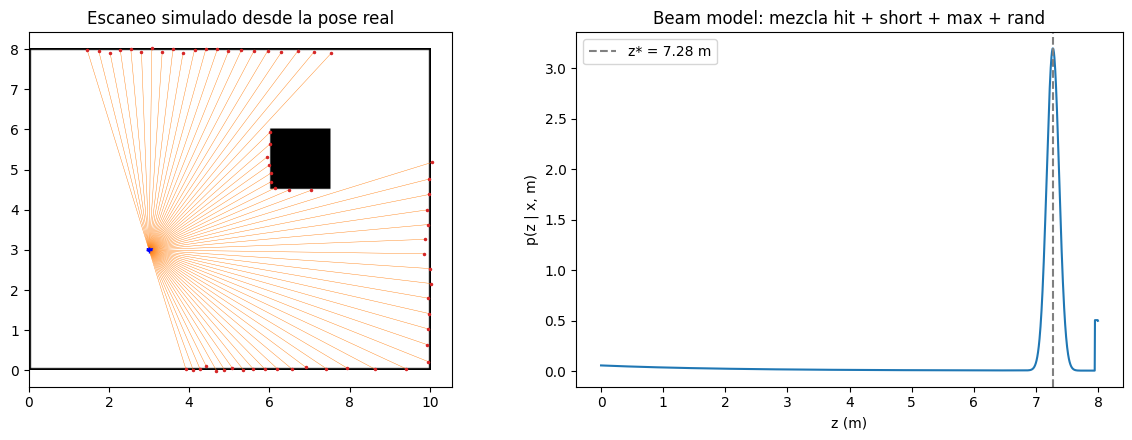

In [14]:
from scipy import ndimage

# ---- Map: 10 x 8 m room with a box, as an occupancy grid (1 = occupied) ----
res = 0.05                                   # cell size (m)
grid = np.zeros((int(8/res), int(10/res)))   # rows = y, cols = x
grid[0, :] = grid[-1, :] = grid[:, 0] = grid[:, -1] = 1
grid[int(4.5/res):int(6/res), int(6/res):int(7.5/res)] = 1  # box

def ray_cast(pose, angles, z_max=8., step=res/2):
    # Ideal range z* of every beam from 'pose' (column 3x1) to the first occupied cell
    z = np.full(len(angles), z_max)
    for k, a in enumerate(angles):
        ang = pose[2, 0] + a
        for d in np.arange(0, z_max, step):
            i = int((pose[1, 0] + d*np.sin(ang))/res)
            j = int((pose[0, 0] + d*np.cos(ang))/res)
            if not (0 <= i < grid.shape[0] and 0 <= j < grid.shape[1]) or grid[i, j]:
                z[k] = d
                break
    return z

z_max = 8.
angles = np.linspace(-np.pi/2, np.pi/2, 61)   # 180º field of view, 61 beams
x_true = np.vstack([3., 3., 0.3])
rng = np.random.default_rng(1)
z_ideal = ray_cast(x_true, angles, z_max)
z_scan = np.clip(z_ideal + rng.normal(0, 0.05, len(angles)), 0, z_max)

# ---- Beam model for one beam ----
def beam_model(z, z_star, z_max, w=(0.8, 0.1, 0.05, 0.05), sigma=0.1, lam=0.5):
    z_hit, z_short, z_mx, z_rand = w
    p_hit = np.exp(-0.5*((z - z_star)/sigma)**2)/(np.sqrt(2*np.pi)*sigma)
    p_short = np.where(z < z_star, lam*np.exp(-lam*z)/(1 - np.exp(-lam*z_star)), 0)
    p_max = np.where(np.abs(z - z_max) < 0.05, 1/0.1, 0)   # narrow uniform around z_max
    p_rand = np.where(z < z_max, 1/z_max, 0)
    return z_hit*p_hit + z_short*p_short + z_mx*p_max + z_rand*p_rand

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axs[0]
ax.imshow(grid, origin='lower', extent=[0, 10, 0, 8], cmap='Greys')
ends = np.c_[x_true[0, 0] + z_scan*np.cos(x_true[2, 0] + angles), x_true[1, 0] + z_scan*np.sin(x_true[2, 0] + angles)]
for e in ends:
    ax.plot([x_true[0, 0], e[0]], [x_true[1, 0], e[1]], color='tab:orange', linewidth=.3)
ax.plot(ends[:, 0], ends[:, 1], '.', color='tab:red', markersize=3)
DrawRobot(fig, ax, x_true, axis_percent=0.03, color='blue', linewidth=1)
ax.set_title('Escaneo simulado desde la pose real')

zs = np.linspace(0, z_max, 2000)
k = 30   # central beam
axs[1].plot(zs, beam_model(zs, z_ideal[k], z_max))
axs[1].axvline(z_ideal[k], color='gray', linestyle='--', label=f'z* = {z_ideal[k]:.2f} m')
axs[1].set_xlabel('z (m)'); axs[1].set_ylabel('p(z | x, m)')
axs[1].set_title('Beam model: mezcla hit + short + max + rand')
axs[1].legend()
plt.tight_layout()

Pose real: (3.00, 3.00); máximo de la verosimilitud: (2.95, 3.00)
p(z|x_max) / p(z|x_max + 0.25 m en x) = exp(65.8)


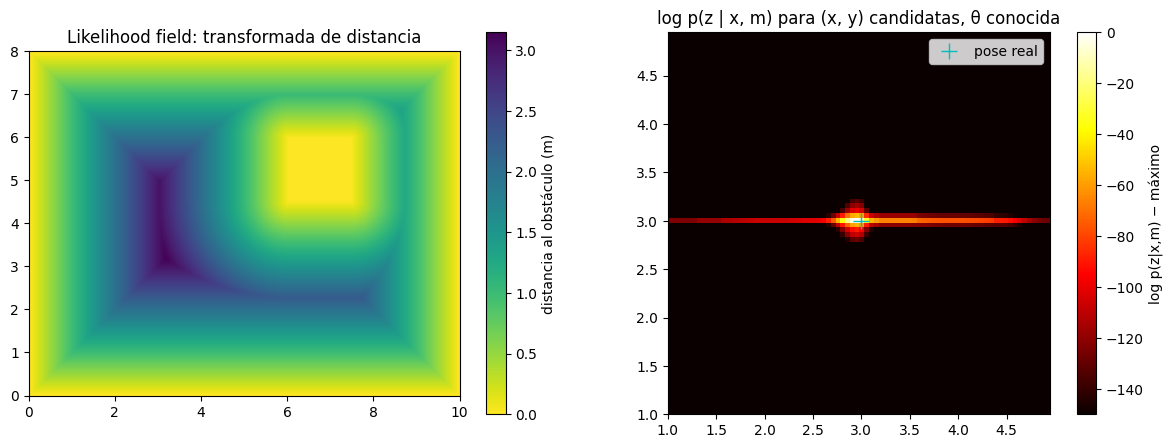

In [15]:
# ---- Likelihood field: distance from every cell to the nearest obstacle (computed once) ----
dist_map = ndimage.distance_transform_edt(grid == 0)*res

def likelihood_field_loglik(pose, z, angles, z_max, sigma=0.1, z_hit=0.9, z_rand=0.1):
    valid = z < z_max                                     # max-range readings are discarded
    a = pose[2, 0] + angles[valid]
    ex = pose[0, 0] + z[valid]*np.cos(a)
    ey = pose[1, 0] + z[valid]*np.sin(a)
    i = np.floor(ey/res).astype(int)
    j = np.floor(ex/res).astype(int)
    inside = (i >= 0) & (i < grid.shape[0]) & (j >= 0) & (j < grid.shape[1])
    d = np.full(len(ex), 1.0)                             # endpoints outside the map: far from any obstacle
    d[inside] = dist_map[i[inside], j[inside]]
    p = z_hit*np.exp(-0.5*(d/sigma)**2)/(np.sqrt(2*np.pi)*sigma) + z_rand/z_max
    return np.sum(np.log(p))                              # product of beams -> sum of logs

xs = np.arange(1., 5., 0.05)
ys = np.arange(1., 5., 0.05)
L = np.array([[likelihood_field_loglik(np.vstack([x, y, x_true[2, 0]]), z_scan, angles, z_max) for x in xs] for y in ys])
iy, ix = np.unravel_index(np.argmax(L), L.shape)
print(f'Pose real: ({x_true[0,0]:.2f}, {x_true[1,0]:.2f}); máximo de la verosimilitud: ({xs[ix]:.2f}, {ys[iy]:.2f})')

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
im = axs[0].imshow(dist_map, origin='lower', extent=[0, 10, 0, 8], cmap='viridis_r')
plt.colorbar(im, ax=axs[0], label='distancia al obstáculo (m)')
axs[0].set_title('Likelihood field: transformada de distancia')
# The product of 61 beams is extremely peaked, so the log-likelihood is shown (clipped for visibility)
print(f'p(z|x_max) / p(z|x_max + 0.25 m en x) = exp({L[iy, ix] - L[iy, ix + 5]:.1f})')
im = axs[1].imshow(np.maximum(L - L.max(), -150), origin='lower', extent=[xs[0], xs[-1], ys[0], ys[-1]], cmap='hot')
plt.colorbar(im, ax=axs[1], label='log p(z|x,m) − máximo')
axs[1].plot(x_true[0, 0], x_true[1, 0], 'c+', markersize=12, label='pose real')
axs[1].set_title('log p(z | x, m) para (x, y) candidatas, θ conocida')
axs[1].legend()
plt.tight_layout()

Pose relativa real  = [0.331 0.055 0.08 ]
Pose relativa (ICP) = [0.328 0.057 0.077]


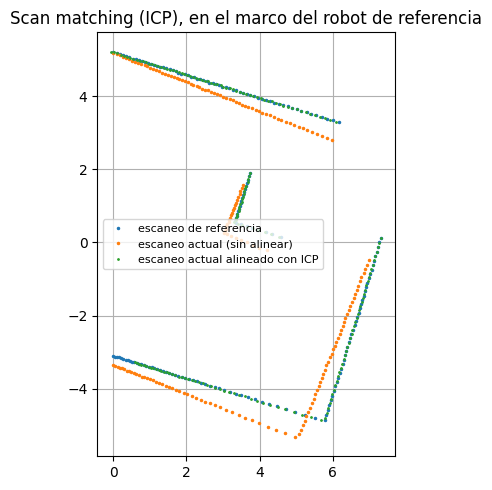

In [16]:
# ---- Scan matching with ICP (point-to-point, closed-form SVD solution) ----
def scan_to_points(z, angles, z_max):
    valid = z < z_max
    return np.c_[z[valid]*np.cos(angles[valid]), z[valid]*np.sin(angles[valid])]   # robot frame

def icp(ref, cur, iters=30):
    R, t = np.eye(2), np.zeros(2)
    for _ in range(iters):
        moved = cur @ R.T + t
        nn = ref[np.argmin(((moved[:, None, :] - ref[None, :, :])**2).sum(axis=2), axis=1)]  # closest points
        mu_m, mu_r = moved.mean(axis=0), nn.mean(axis=0)
        U, _, Vt = np.linalg.svd((moved - mu_m).T @ (nn - mu_r))
        dR = Vt.T @ U.T
        if np.linalg.det(dR) < 0:                       # avoid reflections
            Vt[-1] *= -1; dR = Vt.T @ U.T
        R, t = dR @ R, dR @ t + mu_r - dR @ mu_m
    return np.vstack([t[0], t[1], np.arctan2(R[1, 0], R[0, 0])])

angles_icp = np.linspace(-np.pi/2, np.pi/2, 181)
x_ref = np.vstack([3., 3., 0.3])
x_cur = np.vstack([3.3, 3.15, 0.38])                    # the robot has moved a bit
ref = scan_to_points(ray_cast(x_ref, angles_icp, z_max), angles_icp, z_max)
cur = scan_to_points(ray_cast(x_cur, angles_icp, z_max), angles_icp, z_max)

dx_icp = icp(ref, cur)
dx_true = tinv(x_ref)
dx_true = tcomp(dx_true, x_cur)                         # true relative pose: (-x_ref) (+) x_cur
print('Pose relativa real  =', dx_true.ravel().round(3))
print('Pose relativa (ICP) =', dx_icp.ravel().round(3))

fig, ax = plt.subplots(figsize=(6, 5))
aligned = cur @ np.array([[np.cos(dx_icp[2, 0]), -np.sin(dx_icp[2, 0])], [np.sin(dx_icp[2, 0]), np.cos(dx_icp[2, 0])]]).T + dx_icp[0:2, 0]
ax.plot(ref[:, 0], ref[:, 1], '.', markersize=3, label='escaneo de referencia')
ax.plot(cur[:, 0], cur[:, 1], '.', markersize=3, label='escaneo actual (sin alinear)')
ax.plot(aligned[:, 0], aligned[:, 1], '.', markersize=2, label='escaneo actual alineado con ICP')
ax.set_aspect('equal'); ax.grid(); ax.legend(fontsize=8)
ax.set_title('Scan matching (ICP), en el marco del robot de referencia')
plt.tight_layout()

**Observaciones del ejemplo:**

- **Beam model:** la mezcla tiene un pico gaussiano estrecho en $z^*$, una cola exponencial antes (obstáculos inesperados), un pico en $z_{max}$ (rayos sin eco) y un suelo uniforme. Ese suelo hace que una sola lectura errónea no anule la verosimilitud de una pose buena.
- **Likelihood field:** el máximo de la verosimilitud está a 5 cm de la pose real (el paso de la rejilla de posiciones candidatas). La verosimilitud es **extremadamente picuda**: como se multiplican 61 rayos, desplazarse solo 25 cm en $x$ la divide por $e^{66}$, y por eso se dibuja su logaritmo. En escala logarítmica aparece una **banda horizontal** en $y = 3$: al moverse en $x$, los rayos que llegan a las paredes de arriba y abajo siguen cayendo sobre ellas, así que la $y$ queda muy bien determinada y la $x$ depende solo de la pared derecha y la caja. Es la misma idea que en los pasillos: un sensor de rango localiza bien en la dirección perpendicular a las paredes y mal a lo largo de ellas.
- **ICP:** recupera la pose relativa entre los dos escaneos con un error de pocos milímetros y milésimas de radián, mucho mejor que la odometría de las ruedas. Si el desplazamiento inicial fuera grande, los emparejamientos de los primeros pasos serían malos y podría converger a un mínimo local.

<span style="color:green">***END OF OPTIONAL PART***</span>